# Pipeline de notícias (GDELT) — revisão e base diária

**Semana de 08/10.** Este notebook leva para um script reprodutível (`data_processing/nlp_processing.py`) o que
estava só no `nstructured_data.ipynb` e revisa duas decisões da Entrega 1:

1. **Viés de composição das fontes**: cada veículo tem um "tom de base" diferente, e a mistura de fontes muda muito
   ao longo dos anos. Sem correção, o sentimento médio diário mede *quem* publicou, e não *o que* aconteceu.
2. **Escolha do número de clusters (k)**: na Entrega 1, k = 10 foi escolhido pelo maior Silhouette entre 2 e 10.
   Aqui mostramos que o Silhouette não tem máximo interior nesta base e trocamos o critério por **estabilidade**.

Ao final, a base diária de notícias é salva em `data/news_daily.csv` para a integração com os dados estruturados.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

DATA = Path.cwd().parent / "data"
ALPHA = 0.05

# Mesma paleta e tema do struc_data.ipynb
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GRAY = "#8a8985"
CMAP_DIV = sns.diverging_palette(250, 15, s=75, l=50, center="light", as_cmap=True)
sns.set_theme(style="whitegrid", rc={
    "axes.prop_cycle": plt.cycler(color=C), "axes.edgecolor": "#d6d5d0", "grid.color": "#ecebe7",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

def veredito(p, h0):
    print(f"   H0: {h0}")
    print(f"   p-valor = {p:.4g} -> {'REJEITA' if p < ALPHA else 'NÃO rejeita'} H0 (α = {ALPHA})")

In [2]:
from data_processing.nlp_processing import NewsProcessing

proc = NewsProcessing()
news = proc.load_news()
news[["EventTimestamp", "Source", "SentimentScore", "ToneAdj"]].head()

Notícias únicas: 79,186 | 2017-01-01 a 2026-01-31


,EventTimestamp,Source,SentimentScore,ToneAdj
0,2017-01-01 15:30:00+00:00,coindesk.com,0.3846,1.2670
1,2017-01-01 16:15:00+00:00,coindesk.com,0.8280,0.4434
2,2017-01-01 18:00:00+00:00,coindesk.com,0.2070,-0.3993
3,2017-01-01 22:45:00+00:00,coindesk.com,0.4651,-0.0081
4,2017-01-02 11:00:00+00:00,reuters.com,-1.8767,-0.9943


### 1. Composição das fontes ao longo do tempo

A busca no GDELT foi restrita a 5 fontes (Bloomberg, Reuters, CoinDesk, Cointelegraph e The Block). A tabela e o gráfico
mostram quantas notícias cada fonte contribui por ano e o tom médio de cada uma.

Source,bloomberg.com,coindesk.com,cointelegraph.com,reuters.com,theblock.co
EventTimestamp,,,,,
2017,1121,2309,2012,4348,0
2018,1367,3089,3850,5018,0
2019,57,2718,1866,2782,0
2020,36,3218,1871,2089,0
2021,86,151,2979,5640,0
2022,655,0,2441,521,0
2023,892,3390,5124,685,0
2024,486,3408,7499,303,1
2025,390,4112,1590,239,0


,count,mean,std
Source,,,
theblock.co,1,-4.3939,NaN
bloomberg.com,5112,-1.6987,3.1465
reuters.com,21640,-1.2973,2.3452
cointelegraph.com,29816,-0.7178,2.7164
coindesk.com,22617,-0.5174,2.6052


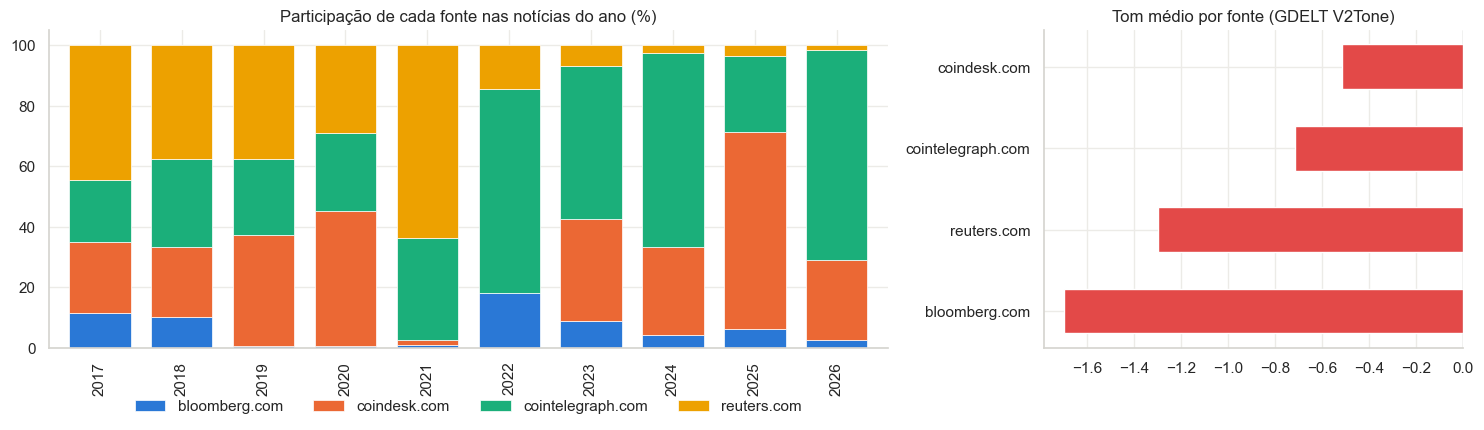

Kruskal-Wallis: tom por fonte
   H0: mesma distribuição de tom em todas as fontes
   p-valor = 0 -> REJEITA H0 (α = 0.05)


In [3]:
comp = pd.crosstab(news["EventTimestamp"].dt.year, news["Source"])
display(comp)

tom_fonte = news.groupby("Source")["SentimentScore"].agg(["count", "mean", "std"]).sort_values("mean")
display(tom_fonte)

share = comp.div(comp.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})
share.drop(columns=["theblock.co"], errors="ignore").plot(kind="bar", stacked=True, ax=axes[0], width=0.75,
                                                         color=C[:4], edgecolor="white", linewidth=0.5)
axes[0].set_title("Participação de cada fonte nas notícias do ano (%)")
axes[0].set_xlabel("")
axes[0].legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
t = tom_fonte.drop(index="theblock.co", errors="ignore")
axes[1].barh(t.index, t["mean"], color=C[7], height=0.55)
axes[1].axvline(0, color="#52514e", lw=0.8)
axes[1].set_title("Tom médio por fonte (GDELT V2Tone)")
plt.tight_layout()
plt.show()

# Teste: o tom difere entre as fontes?
grupos = [g["SentimentScore"].values for s, g in news.groupby("Source") if len(g) > 100]
print("Kruskal-Wallis: tom por fonte")
veredito(stats.kruskal(*grupos).pvalue, "mesma distribuição de tom em todas as fontes")

**Leitura:** o tom de base varia bastante entre as fontes (Bloomberg e Reuters são bem mais negativas que CoinDesk e
Cointelegraph), e a composição muda muito: a CoinDesk praticamente some em 2021–2022 e a Bloomberg quase não aparece em
2019–2021 (lacunas de indexação do GDELT). Um sentimento médio "bruto" cairia artificialmente nos anos em que a
Bloomberg/Reuters pesam mais.

**Decisão:** criar o tom ajustado `ToneAdj` = tom da notícia − média histórica da fonte. A média é *expansiva e
defasada* (usa só notícias anteriores), para não usar informação futura.

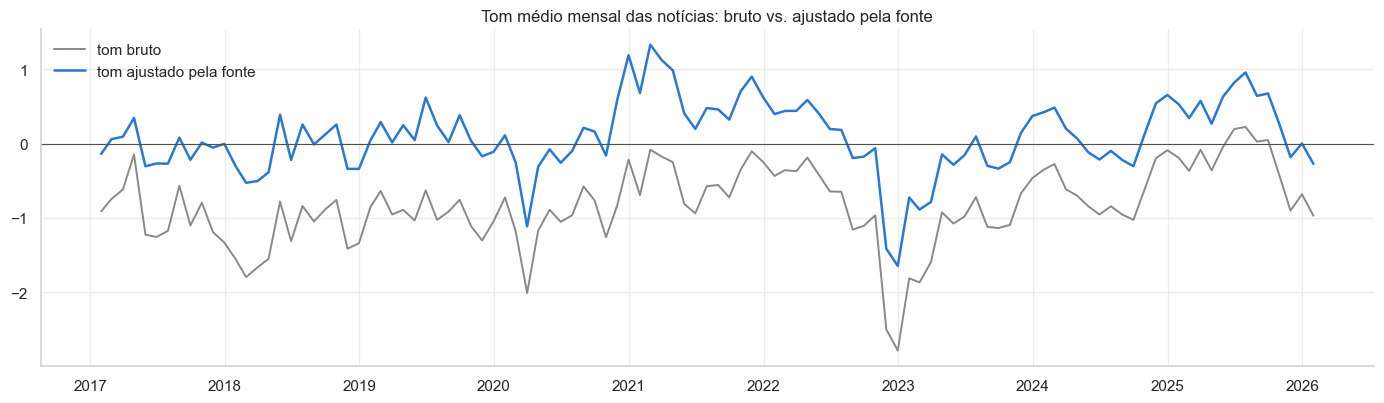

In [4]:
mensal = news.set_index("EventTimestamp").resample("ME")[["SentimentScore", "ToneAdj"]].mean()
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(mensal.index, mensal["SentimentScore"], color=GRAY, lw=1.4, label="tom bruto")
ax.plot(mensal.index, mensal["ToneAdj"], color=C[0], lw=1.8, label="tom ajustado pela fonte")
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_title("Tom médio mensal das notícias: bruto vs. ajustado pela fonte")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 2. Matriz notícia × conceito

Mesma construção da Entrega 1: remoção da stop-word de domínio `ECON_BITCOIN` (presente em 99,6% das notícias),
seleção dos 80 temas e das 50 organizações mais frequentes (Pareto/Zipf) e matriz binária notícia × conceito.

In [5]:
X = proc.build_concept_matrix()

Matriz notícia x conceito: (79186, 130) | cobertura: 98.58% das notícias


### 3. Quantos clusters? Revisão do critério

Na Entrega 1, k foi escolhido pelo maior **Silhouette** entre 2 e 10, e o máximo caiu justamente em k = 10, a borda do
intervalo testado. Testando um intervalo maior, o Silhouette continua subindo até k = 60: ele premia pares de conceitos
quase duplicados (ex.: *York Stock Exchange* e *New York Stock Exchange*) e não tem máximo interior. Ou seja, **não serve
para escolher k nesta base**.

**Novo critério: estabilidade.** Reamostramos as *notícias* com bootstrap (40 vezes), refazemos o agrupamento dos
conceitos e medimos o quanto ele concorda com o agrupamento da base completa (ARI, Adjusted Rand Index: 1 = idêntico,
0 = acaso). Um agrupamento que muda quando a amostra muda não é uma estrutura real dos dados. Também olhamos o **salto no
dendrograma**: um salto grande na altura de fusão indica um corte "natural".

**Regra:** maior k com ARI médio ≥ 0,90 (agrupamento reprodutível, mas o mais detalhado possível).

k escolhido: 11 (ARI médio = 0.938)


,silhouette,ari_medio,ari_min,salto_dendrograma
k,,,,
4,0.0230,0.9730,0.9060,0.2610
5,0.0390,0.9730,0.9030,0.1660
6,0.0480,0.9730,0.9030,0.0580
7,0.0500,0.9670,0.8500,0.0370
8,0.0570,0.9240,0.7320,0.0720
9,0.0590,0.9210,0.7750,0.0620
10,0.0680,0.8930,0.7680,0.0050
11,0.0750,0.9380,0.8300,0.0610
12,0.0810,0.8840,0.7140,0.0150


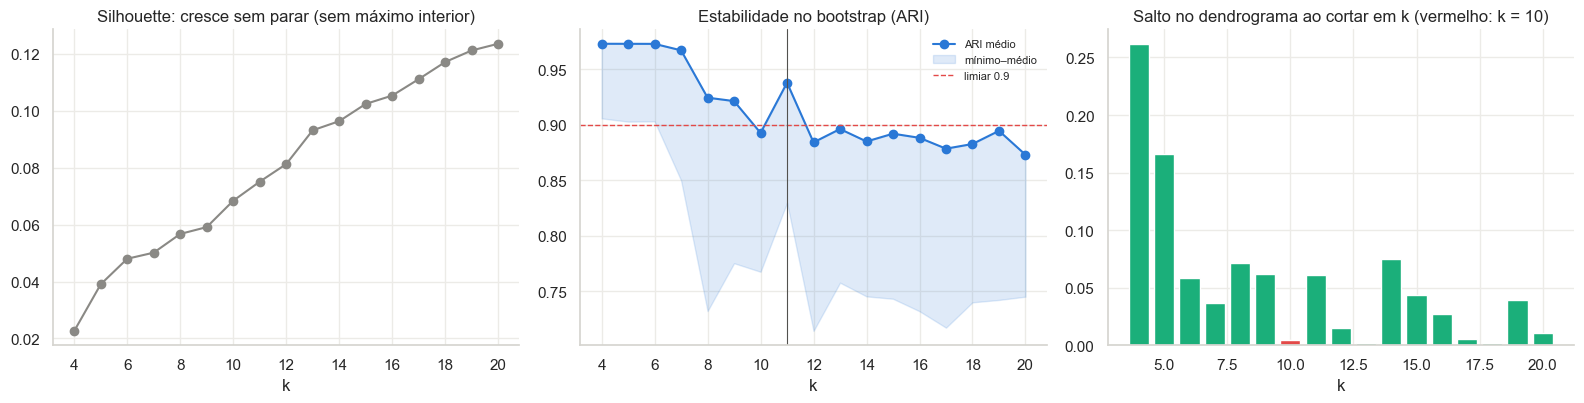

In [6]:
k, diag = proc.select_k()
display(diag.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(diag.index, diag["silhouette"], marker="o", color=GRAY)
axes[0].set_title("Silhouette: cresce sem parar (sem máximo interior)")
axes[1].plot(diag.index, diag["ari_medio"], marker="o", color=C[0], label="ARI médio")
axes[1].fill_between(diag.index, diag["ari_min"], diag["ari_medio"], color=C[0], alpha=0.15, label="mínimo–médio")
axes[1].axhline(proc.ARI_MIN, color=C[7], ls="--", lw=1, label=f"limiar {proc.ARI_MIN}")
axes[1].axvline(k, color="#52514e", lw=0.8)
axes[1].set_title("Estabilidade no bootstrap (ARI)")
axes[1].legend(frameon=False, fontsize=8)
axes[2].bar(diag.index, diag["salto_dendrograma"], color=C[2])
axes[2].bar([10], diag.loc[[10], "salto_dendrograma"], color=C[7])
axes[2].set_title("Salto no dendrograma ao cortar em k (vermelho: k = 10)")
for ax in axes:
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()

**Leitura:** o k = 10 da Entrega 1 era justamente um corte **instável**: a fusão que leva de 11 para 10 clusters
acontece quase na mesma altura que a anterior (salto ≈ 0,005), então pequenas mudanças na amostra trocam os conceitos
de grupo, o que aparece como uma queda local do ARI em k = 10. O critério escolhe **k = 11**: estável (ARI ≈ 0,94) e com
um salto claro no dendrograma. A escolha se repete com outras sementes do bootstrap (testado com 42 e 7).

In [7]:
labels = proc.cluster_concepts(k)
tabela = proc.cluster_table()

cobertura = pd.Series({c + 1: proc.X[:, labels == c].any(axis=1).mean() for c in range(k)}, name="cobertura")
resumo = (tabela.groupby("cluster")
          .agg(n_conceitos=("conceito", "size"), nome=("nome_cluster", "first"),
               conceitos=("conceito", lambda s: ", ".join(s.str.replace("TAG_", "").str.replace("ORG_", "@").head(8))))
          .join(cobertura))
with pd.option_context("display.max_colwidth", 140):
    display(resumo)

,n_conceitos,nome,conceitos,cobertura
cluster,,,,
1,22,WB_698_TRADE | TAX_ECON_PRICE | Reuters,"WB_698_TRADE, TAX_ECON_PRICE, @Reuters, ECON_STOCKMARKET, WB_1104_MACROECONOMIC_VULNERABILITY_AND_DEBT, TAX_FNCACT_TRADERS, IDEOLOGY, EC...",0.8239
2,20,UNGP_FORESTS_RIVERS_OCEANS | CRISISLEX_CRISISLEXREC | CRISISLEX_C07_SAFETY,"UNGP_FORESTS_RIVERS_OCEANS, CRISISLEX_CRISISLEXREC, CRISISLEX_C07_SAFETY, TAX_FNCACT_CEO, @United States, EPU_CATS_MIGRATION_FEAR_FEAR, ...",0.7903
3,10,USPEC_POLICY1 | EPU_ECONOMY_HISTORIC | USPEC_POLITICS_GENERAL1,"USPEC_POLICY1, EPU_ECONOMY_HISTORIC, USPEC_POLITICS_GENERAL1, GENERAL_GOVERNMENT, LEADER, EPU_ECONOMY, EPU_POLICY_GOVERNMENT, EPU_POLICY...",0.7090
4,40,MEDIA_SOCIAL | TAX_FNCACT_DIRECTOR | Twitter,"MEDIA_SOCIAL, TAX_FNCACT_DIRECTOR, @Twitter, @Bloomberg, @Facebook, @Thomson Reuters, @European Union, @Blackrock",0.4602
5,10,EPU_CATS_REGULATION | EPU_POLICY_REGULATORY | LEGISLATION,"EPU_CATS_REGULATION, EPU_POLICY_REGULATORY, LEGISLATION, EPU_CATS_FINANCIAL_REGULATION, TAX_FNCACT_REGULATORS, EPU_POLICY_LAW, EPU_POLIC...",0.4111
6,6,WB_696_PUBLIC_SECTOR_MANAGEMENT | WB_831_GOVERNANCE | WB_840_JUSTICE,"WB_696_PUBLIC_SECTOR_MANAGEMENT, WB_831_GOVERNANCE, WB_840_JUSTICE, CORRUPTION, WB_1014_CRIMINAL_JUSTICE, WB_832_ANTI_CORRUPTION",0.3734
7,7,WB_1920_FINANCIAL_SECTOR_DEVELOPMENT | EPU_CATS_MONETARY_POLICY | WB_318_FINANCIAL_ARCHITECTURE_AND_BANKING,"WB_1920_FINANCIAL_SECTOR_DEVELOPMENT, EPU_CATS_MONETARY_POLICY, WB_318_FINANCIAL_ARCHITECTURE_AND_BANKING, WB_1234_BANKING_INSTITUTIONS,...",0.3371
8,5,WB_133_INFORMATION_AND_COMMUNICATION_TECHNOLOGIES | WB_678_DIGITAL_GOVERNMENT | WB_694_BROADCAST_AND_MEDIA,"WB_133_INFORMATION_AND_COMMUNICATION_TECHNOLOGIES, WB_678_DIGITAL_GOVERNMENT, WB_694_BROADCAST_AND_MEDIA, ECON_ENTREPRENEURSHIP, @Digita...",0.3273
9,4,TAX_FNCACT_CHIEF | TAX_FNCACT_EXECUTIVE | TAX_FNCACT_OFFICER,"TAX_FNCACT_CHIEF, TAX_FNCACT_EXECUTIVE, TAX_FNCACT_OFFICER, TAX_MILITARY_TITLE_OFFICER",0.1945


**Interpretação dos clusters** (nome dado pelos conceitos mais frequentes):

| Cluster | Tema dominante |
|---|---|
| 1 | comércio, preço e mercado (núcleo econômico, Reuters) |
| 2 | crise, segurança e risco (CRISISLEX) |
| 3 | política e incerteza econômica (EPU, política americana) |
| 4 | mídia social e empresas de tecnologia/finanças (Twitter, Facebook, BlackRock) |
| 5 | **regulação** e legislação (SEC, reguladores) |
| 6 | governança, justiça e corrupção (processos, fraudes) |
| 7 | **política monetária** e sistema bancário |
| 8 | tecnologia digital e governo digital |
| 9 | executivos e cargos (CEO, diretores) |
| 10 | **mineração e energia** |
| 11 | Bolsa de Nova York (par de organizações) |

Os clusters 5, 7 e 10 têm interpretação econômica direta para o BTC e são os candidatos mais naturais a sinal.

### 4. Base diária de notícias

Agregação por **dia UTC**, o mesmo fechamento do candle diário do BTC. Guardamos **somas e contagens** (e não só médias),
para que médias móveis ponderadas pelo número de notícias possam ser calculadas depois de forma exata, inclusive em dias
sem notícia. Por cluster: número de notícias do cluster e soma do tom ajustado dessas notícias.

Notícias únicas: 79,186 | 2017-01-01 a 2026-01-31


Matriz notícia x conceito: (79186, 130) | cobertura: 98.58% das notícias


Base diária salva: (3318, 30) | clusters: 11
Período: 2017-01-01 a 2026-01-31 | dias sem notícia: 33


,mean,std,min,max
news_count,23.8656,21.2917,0.0000,234.0000
news_tone_sum,-21.0574,35.9934,-483.8504,178.0661
news_tone_adj_sum,1.8705,25.0718,-195.7612,336.6939
news_tone_mean,-0.8274,1.0458,-6.9599,3.6728
news_tone_adj_mean,0.0488,1.0279,-5.8055,5.1066
news_tone_std,2.4271,0.8456,0.0000,8.5323
news_neg_count,6.7212,8.1953,0.0000,123.0000
news_pos_count,2.4852,2.7630,0.0000,34.0000
clu1_count,19.6640,19.1514,0.0000,226.0000
clu1_tone_adj_sum,2.0359,22.5061,-168.2404,272.1015


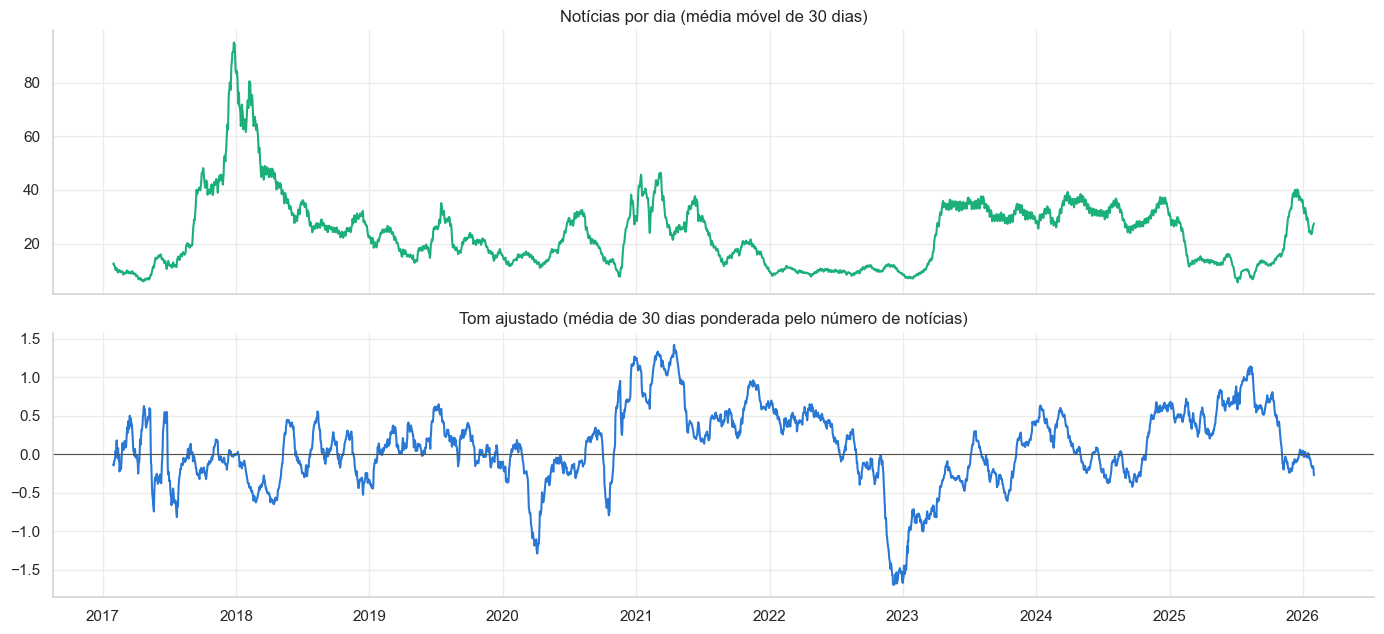

In [8]:
daily, tabela = proc.run(k=k)
print(f"Período: {daily.index.min().date()} a {daily.index.max().date()} | dias sem notícia: {(daily['news_count'] == 0).sum()}")
display(daily.describe().T[["mean", "std", "min", "max"]])

fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
axes[0].plot(daily.index, daily["news_count"].rolling(30).mean(), color=C[2])
axes[0].set_title("Notícias por dia (média móvel de 30 dias)")
tone30 = daily["news_tone_adj_sum"].rolling(30).sum() / daily["news_count"].rolling(30).sum()
axes[1].plot(daily.index, tone30, color=C[0])
axes[1].axhline(0, color="#52514e", lw=0.8)
axes[1].set_title("Tom ajustado (média de 30 dias ponderada pelo número de notícias)")
plt.tight_layout()
plt.show()

### 5. Conclusões

1. O pipeline de notícias agora roda por script (`python -m data_processing.nlp_processing`), com saída em
   `data/news_daily.csv`, `data/news_clusters.csv` e `data/news_k_selection.csv`.
2. **Tom ajustado pela fonte:** as fontes têm tons de base muito diferentes e a composição muda entre os anos; o ajuste
   remove esse viés usando só informação passada.
3. **k = 11 por estabilidade**, no lugar de k = 10 por Silhouette. O Silhouette cresce de forma monotônica nesta base e
   o k = 10 era um corte instável. Os novos clusters são reprodutíveis (ARI ≈ 0,94) e têm interpretação clara
   (regulação, política monetária, mineração/energia...).
4. Limitações: a cobertura do GDELT por fonte tem lacunas (CoinDesk em 2021–2022, Bloomberg em 2019–2021), e o
   agrupamento de conceitos usa o vocabulário de 2017–2026 inteiro. Isso é aceitável porque o agrupamento não usa preço
   nem retorno (é não supervisionado), mas fica registrado.